In [16]:
import altair as alt
import pandas as pd
import glob
import matplotlib.pyplot as plt

In [4]:
# files = glob.glob("data/*.csv")
# df_list = [pd.read_csv(file) for file in files]
# merged_df = pd.concat(df_list, ignore_index=True)
# merged_df.to_csv("combined_output.csv", index=False)

KeyboardInterrupt: 

In [6]:
data = pd.read_csv("combined_output.csv")
data.head()

,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_RANGE,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE
0,201509,18,1544,201509,18,1553,99979,602745,ILLINOIS,17,...,4.0,W,MONEE,41.4164,-87.86,41.4266,-87.8119,A low pressure system moved towards northern I...,A spotter was located near Green Garden Rd and...,CSV
1,201501,27,1200,201501,28,400,92561,559139,NEW HAMPSHIRE,33,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,An area of low pressure developed off the Delm...,"Once blizzard conditions subsided, snow and bl...",CSV
2,201501,24,700,201501,24,2100,92625,555067,NEW HAMPSHIRE,33,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,An area of low pressure moving rapidly northea...,NaN,CSV
3,201501,27,600,201501,27,1200,92561,554564,NEW HAMPSHIRE,33,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,An area of low pressure developed off the Delm...,NaN,CSV
4,201502,14,800,201502,15,1700,93895,564438,NEW HAMPSHIRE,33,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Low pressure dropping southeast from Canada on...,NaN,CSV


In [8]:
filtered_df = data[data["EVENT_TYPE"] == "Tornado"]
filtered_df.to_csv("tornado.csv", index=False)

In [11]:
df = pd.read_csv("tornado.csv")
df.head()

,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_RANGE,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE
0,201509,18,1544,201509,18,1553,99979,602745,ILLINOIS,17,...,4.00,W,MONEE,41.4164,-87.8600,41.4266,-87.8119,A low pressure system moved towards northern I...,A spotter was located near Green Garden Rd and...,CSV
1,201512,23,1923,201512,23,1942,101491,607148,TENNESSEE,47,...,2.49,NW,SUMMERTOWN,35.3183,-87.5770,35.4563,-87.3303,An unusually powerful upper level trough moved...,"This strong, long-track EF3 tornado touched do...",CSV
2,201512,23,1942,201512,23,1948,101491,607151,TENNESSEE,47,...,10.32,SE,GORDONSBURG,35.4563,-87.3303,35.4844,-87.2797,An unusually powerful upper level trough moved...,"This strong, long-track EF3 tornado touched do...",CSV
3,201512,23,1948,201512,23,1952,101491,607152,TENNESSEE,47,...,1.96,NNE,SANDY HOOK,35.4844,-87.2797,35.5067,-87.2384,An unusually powerful upper level trough moved...,"This strong, long-track EF3 tornado touched do...",CSV
4,201512,23,2221,201512,23,2224,101491,607155,TENNESSEE,47,...,0.76,SE,LANCASTER,36.1016,-85.8869,36.1218,-85.8410,An unusually powerful upper level trough moved...,This EF2 tornado touched down on Helton Creek ...,CSV


In [26]:
s = df["DAMAGE_PROPERTY"].astype(str).str.upper().str.replace(",", "", regex=False)
mult = s.str[-1].map({"K": 1e3, "M": 1e6, "B": 1e9}).fillna(1)
num = pd.to_numeric(s.str.rstrip("KMB"), errors="coerce")
df["DAMAGE_PROPERTY"] = num * mult

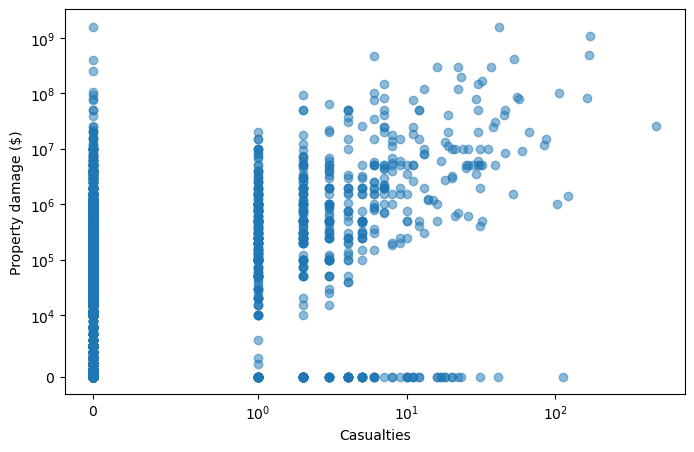

In [29]:
df["damage"] = df["DAMAGE_PROPERTY"]
df["casualties"] = df[["INJURIES_DIRECT", "INJURIES_INDIRECT",
                       "DEATHS_DIRECT", "DEATHS_INDIRECT"]].sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["casualties"], df["damage"], alpha=0.5)
ax.set_yscale("symlog", linthresh=1e4)   
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("Casualties")
ax.set_ylabel("Property damage ($)")
plt.show()